In [1]:
import numpy as np
import pandas as pd
import emcee
from io import StringIO
CO, H2O, CO2, H2, CH2 = range(5)

In [2]:
raw_txt = """Experiment block\tTemp\tCO2 mL/min\tCO mL/min\tAr mL/min\tCO/Ar mL/min\tH2 mL/min\tTotal  mL/min\talpha\tPCO\tPCO2\tPH2
H2COVar\t513\t0\t56.84210526\t6.315789474\t63.15789474\t56.84210526\t120\t0.792973876\t2.368421053\t0\t2.368421053
H2COVar\t513\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.783092833\t1.607142857\t0\t3.214285714
H2COVar\t513\t0\t29.18918919\t3.243243243\t32.43243243\t87.56756757\t120\t0.758648032\t1.216216216\t0\t3.648648649
TempVar(Only CO+H2)\t493.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.828590544\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t513.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.778061766\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t533.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.68652452\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t553.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.570689834\t1.607142857\t0\t3.214285714
TempVar(Only CO+H2)\t573.15\t0\t38.57142857\t4.285714286\t42.85714286\t77.14285714\t120\t0.484066337\t1.607142857\t0\t3.214285714
H2CO2Var\t513.15\t30\t0\t0\t0\t90\t120\t0.018953371\t0\t1.25\t3.75
H2CO2Var\t513.15\t40\t0\t0\t0\t80\t120\t0.024583548\t0\t1.666666667\t3.333333333
H2CO2Var\t513.15\t60\t0\t0\t0\t60\t120\t0.037047515\t0\t2.5\t2.5
TempVar(Only CO2+H2)\t493.15\t40\t0\t0\t0\t80\t120\t0.02664535\t0\t1.666666667\t3.333333333
TempVar(Only CO2+H2)\t513.15\t40\t0\t0\t0\t80\t120\t0.023100337\t0\t1.666666667\t3.333333333
TempVar(Only CO2+H2)\t533.15\t40\t0\t0\t0\t80\t120\t0.01438644\t0\t1.666666667\t3.333333333
TempVar(Only CO2+H2)\t553.15\t40\t0\t0\t0\t80\t120\t0.008155606\t0\t1.666666667\t3.333333333
TempVar(Only CO+CO2+H2)\t493.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.536381781\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t513.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.469369407\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t533.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.26899611\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t553.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.241802475\t0.412844037\t0.825688073\t3.715416667
TempVar(Only CO+CO2+H2)\t573.15\t19.81651376\t9.908256881\t1.01\t11.00917431\t89.17\t120\t0.235135057\t0.412844037\t0.825688073\t3.715416667
ConstH2CO2Var\t513.15\t10\t0\t80\t0\t30\t120\t0.017891062\t0\t0.416666667\t1.25
ConstH2CO2Var\t513.15\t15\t0\t75\t0\t30\t120\t0.022537633\t0\t0.625\t1.25
ConstH2CO2Var\t513.15\t30\t0\t60\t0\t30\t120\t0.034930099\t0\t1.25\t1.25
ConstH2COVar\t513.15\t0\t9.999\t80.001\t11.00917431\t30\t120\t0.627018131\t0.416625\t0\t1.25
ConstH2COVar\t513.15\t0\t15.003\t74.997\t16.67\t30\t120\t0.662211446\t0.625125\t0\t1.25
ConstH2COVar\t513.15\t0\t29.997\t60.007\t33.33\t30\t120\t0.728855629\t1.249875\t0\t1.25
ConstCOH2Var\t513.15\t0\t26.1\t32.68\t29\t58\t116.78\t0.685585374\t1.117485871\t0\t2.483301935
ConstCOH2Var\t513.15\t0\t26.1\t61.68\t29\t29\t116.78\t0.730646513\t1.117485871\t0\t1.241650968
ConstCOH2Var\t513.15\t0\t26.1\t32.68\t29\t58\t116.78\t0.721576582\t1.117485871\t0\t2.483301935
"""


In [3]:
df_raw = pd.read_csv(StringIO(raw_txt), sep=r"\t", engine="python")
df_raw.columns = [str(c).strip().replace("\u00a0", " ") for c in df_raw.columns]

# drop junk
drop_cols = [c for c in df_raw.columns if c.lower().startswith("column")]
df_raw = df_raw.drop(columns=drop_cols, errors="ignore")
df_raw = df_raw.dropna(axis=1, how="all")

rename_map = {
    "Experiment block": "block",
    "Temp": "T",
    "CO2 mL/min": "CO2",
    "CO mL/min": "CO",
    "Ar mL/min": "Ar",
    "CO/Ar mL/min": "CO_Ar",
    "H2 mL/min": "H2",
    "Total  mL/min": "Total",
    "H2:CO ratio": "H2_CO_ratio",
    "H2:CO2 ratio": "H2_CO2_ratio",
}
df = df_raw.rename(columns=rename_map).copy()

required = [
    "block","T","CO2","CO","Ar","CO_Ar","H2","Total",
    "alpha","PCO","PCO2","PH2"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns after cleaning: {missing}\nColumns found: {list(df.columns)}")

for c in required:
    if c != "block":
        df[c] = pd.to_numeric(df[c], errors="coerce")

df["block"] = df["block"].astype(str).str.strip()
df = df.dropna(subset=["block", "T", "alpha"]).copy()

bad_alpha = df[~df["alpha"].between(0.0, 1.0, inclusive="neither")]
if len(bad_alpha) > 0:
    print("Invalid alpha rows (must be 0<alpha<1):")
    display(bad_alpha[["block","T","alpha","CO2","CO","H2"]])
    raise ValueError("Invalid alpha values present.")


In [4]:
R = 8.314462618            # J/mol/K
P  =  1e5  # Pa (absolute)f
T_ref = 500
eps = 1e-12

def logit(a):
    a = np.clip(np.asarray(a, float), eps, 1.0 - eps)
    return np.log(a / (1.0 - a))

def inv_logit(z):
    z = np.asarray(z, float)
    z = np.clip(z, -1000, 1000)
    return 1.0 / (1.0 + np.exp(-z))

In [5]:
def alpha_model(theta, T, C_CO, C_CO2, C_H2):
    k0, Ea, a, b, c = theta

    T = np.asarray(T, float)
    C_CO  = np.asarray(C_CO, float)
    C_CO2 = np.asarray(C_CO2, float)
    C_H2  = np.asarray(C_H2, float)

    CO_term  = (C_CO  + eps)**a
    CO2_term = (C_CO2 + eps)**b

    denom = k0 * np.exp(Ea/R*(1/T-1/T_ref)) * (CO_term + CO2_term)
    alpha = (1+(C_H2**c+eps)/(denom))**(-1)
    return np.clip(alpha, eps, 1.0 - eps)

In [6]:
T_arr  = df["T"].to_numpy(float)
C_CO   = df["CO"].to_numpy(float)
C_CO2  = df["CO2"].to_numpy(float)
C_H2   = df["H2"].to_numpy(float)

alpha_obs = df["alpha"].to_numpy(float)
y_obs = logit(alpha_obs)

def log_likelihood(theta):
    log_k0, Ea, a, b, c, log_sigma = theta
    sigma = np.exp(log_sigma)

    alpha_mu = alpha_model([log_k0, Ea, a, b, c], T_arr, C_CO, C_CO2, C_H2)
    mu = logit(alpha_mu)

    resid = y_obs - mu
    return -0.5 * np.sum((resid / sigma)**2 + 2*np.log(sigma) + np.log(2*np.pi))

def log_prior(theta):
    k0, Ea, a, b, c, log_sigma = theta
    lp = 0.0

    # log_k0 ~ N(0, 5^2)
    lp += -0.5 * (k0 / 0.1)**2 - np.log(0.1 * np.sqrt(2*np.pi))

    # Ea ~ N(Ea_lin, (5e4)^2)
    lp += -0.5 * ((Ea - 5000) / 5e4)**2 - np.log(5e4 * np.sqrt(2*np.pi))

    # bounds
    if not (0.0 <= a <= 3.0 and -3.0 <= b <= 3.0 and 0.0 <= c <= 3.0):
        return -np.inf

    # Half-Cauchy(2.5) on sigma via log_sigma (Jacobian included)
    sigma = np.exp(log_sigma)
    if sigma <= 0:
        return -np.inf
    lp += np.log(2/np.pi) - np.log(1 + (sigma/2.5)**2) + log_sigma
    return lp

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta)


In [7]:
rng = np.random.default_rng(42)

theta0 = np.array([
    1.0,   # k0
    50001,         # Ea
    1.0,           # a
    1.0,           # b
    1.0,           # c
    np.log(0.5)    # log_sigma
], dtype=float)

ndim = theta0.size
nwalkers = 4 * ndim

p0 = theta0 + rng.normal(
    scale=[0.1, 5e3, 0.15, 0.15, 0.15, 0.15],
    size=(nwalkers, ndim)
)

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

print("\n--- Burn-in ---")
state = sampler.run_mcmc(p0, 5000, progress=True)

sampler.reset()
print("\n--- Production ---")
sampler.run_mcmc(state, 15000, progress=True)



--- Burn-in ---


100%|██████████| 5000/5000 [00:10<00:00, 464.18it/s]



--- Production ---


100%|██████████| 15000/15000 [00:24<00:00, 606.77it/s]


State([[ 1.09019876e-01  4.63504630e+04  1.27285441e+00 -7.85351310e-02
   2.26091144e-01 -1.18463467e+00]
 [ 6.19822440e-02  4.86158538e+04  1.28245090e+00 -6.08606626e-02
   9.61683846e-02 -1.12922233e+00]
 [ 1.38316991e-01  3.83600861e+04  1.31602704e+00 -9.55269163e-02
   3.08638488e-01 -1.02276064e+00]
 [ 1.48185836e-01  3.32409566e+04  1.32769414e+00 -9.36904575e-02
   3.62402773e-01 -1.18678610e+00]
 [ 6.37409142e-02  5.70615690e+04  1.18725528e+00 -1.26052979e-01
   4.19315640e-02 -1.13688914e+00]
 [ 6.41557723e-02  4.71415378e+04  1.20047671e+00 -1.19185033e-01
   6.07846074e-02 -1.22007038e+00]
 [ 9.63803562e-02  4.84599322e+04  1.19768689e+00 -9.73850378e-02
   1.74089847e-01 -1.25535875e+00]
 [ 9.74215149e-02  4.95487961e+04  1.30260295e+00 -4.34915571e-02
   1.99939199e-01 -1.28408501e+00]
 [ 6.55344973e-02  4.15620417e+04  1.27597876e+00 -7.98245912e-02
   1.14864355e-01 -1.18224799e+00]
 [ 9.47607601e-02  2.93555765e+04  1.12167441e+00 -1.14621569e-01
   1.85886338e-01 -

In [8]:
flat = sampler.get_chain(discard=0, thin=10, flat=True)
k0_s, Ea_s, a_s, b_s, c_s, log_sigma_s = [flat[:, i] for i in range(flat.shape[1])]
sigma_s = np.exp(log_sigma_s)

def summarize(x):
    x = np.asarray(x, float)
    return np.mean(x), np.std(x), np.percentile(x, [5, 50, 95])

print("\n--- Posterior summaries ---")
names = ["k0", "Ea", "a", "b", "c", "sigma"]
for nm, arr in zip(names, [k0_s, Ea_s, a_s, b_s, c_s, sigma_s]):
    m, sd, q = summarize(arr)
    print(f"{nm:8s}: mean={m:.6g}, sd={sd:.6g}, 95% CrI=({q[0]:.6g}, {q[2]:.6g})")


--- Posterior summaries ---
k0      : mean=0.0817416, sd=0.0303447, 95% CrI=(0.0480833, 0.14114)
Ea      : mean=44282.8, sd=6277.71, 95% CrI=(33930.3, 54459.2)
a       : mean=1.22101, sd=0.0588424, 95% CrI=(1.12812, 1.31857)
b       : mean=-0.100175, sd=0.0203621, 95% CrI=(-0.122703, -0.0667217)
c       : mean=0.127948, sd=0.0855824, 95% CrI=(0.0130633, 0.286473)
sigma   : mean=0.2845, sd=0.0449549, 95% CrI=(0.221882, 0.366791)


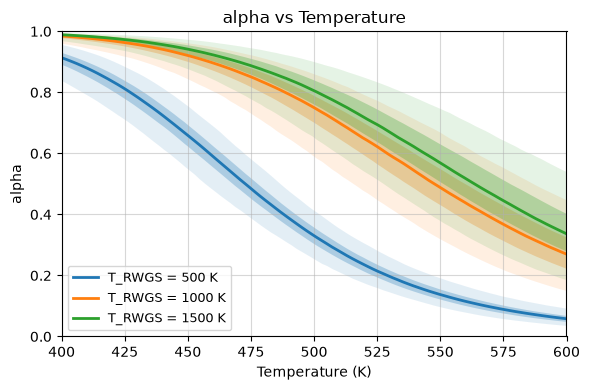

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# --- Original constants from your code (used as means) ---
k_o_sq_mean = 0.113
dEA_mean = -47554.0     # J/mol
T_ref = 500.0
a_mean = 1.027
b_mean = -0.303
c_mean = 0.038
R = 8.314
P = 5e5

# --- Options for uncertainty sampling ---
n_samps = 2000
rng = np.random.default_rng(12345)

# Choose whether to use real posterior draws (if you have them).
# If True, set `draws` to a dict of arrays, e.g. draws = {'k_o_sq': arr, 'dEA': arr, 'a': arr, 'b': arr, 'c': arr}
use_posterior_draws = False
draws = {}  # replace with your arrays if use_posterior_draws = True

# If not using real draws, choose standard deviations for sampling (relative or absolute)
# You can tune these to match the uncertainty you expect.
rel_std_frac = 0.10   # 10% relative std by default for most params
k_o_sq_std = rel_std_frac * abs(k_o_sq_mean)
dEA_std = 5000.0      # absolute std for activation-like parameter (adjust if needed)
a_std = rel_std_frac * max(1e-6, abs(a_mean))
b_std = rel_std_frac * max(1e-6, abs(b_mean))
c_std = rel_std_frac * max(1e-6, abs(c_mean))

# --- Functions (kept the same equilibrium constant and composition formulas) ---
def equilibrium_constant(T):
    # same form you used
    K_eq = np.exp(-13.148 + 1.077 * np.log(T) + 5.44e-4 * T - 1.125e-7 * T**2 + 5693.5 / T - 49170 / T**2)
    return K_eq

def equilibrium_compositions(K_eq):
    sqrtK = np.sqrt(K_eq)
    molefr_CO  = 1.0 / (2.0 * (1.0 + sqrtK))
    molefr_CO2 = sqrtK / (2.0 * (1.0 + sqrtK))
    molefr_H2  = molefr_CO2.copy()
    return molefr_CO, molefr_CO2, molefr_H2

# --- Temperature ranges and reaction temperatures (same as your first code) ---
T_RWGS = np.array([500, 1000, 1500])
T_FT = np.linspace(400, 600, 100)

# --- Prepare sampling of parameters ---
if use_posterior_draws:
    # validate draws dict keys and lengths
    # expected keys: any subset of 'k_o_sq','dEA','a','b','c'
    # If draws arrays have different lengths we sample from them with replacement.
    available_keys = list(draws.keys())
    if not available_keys:
        raise ValueError("use_posterior_draws=True but draws dict is empty. Provide arrays.")
    # build sampled parameter arrays by random choice
    def sample_from_draws(key, n):
        arr = draws[key]
        idx = rng.integers(0, arr.size, size=n)
        return arr[idx]
    k_o_sq_samps = sample_from_draws('k_o_sq', n_samps) if 'k_o_sq' in draws else rng.normal(k_o_sq_mean, k_o_sq_std, n_samps)
    dEA_samps   = sample_from_draws('dEA', n_samps)     if 'dEA' in draws     else rng.normal(dEA_mean, dEA_std, n_samps)
    a_samps     = sample_from_draws('a', n_samps)       if 'a' in draws       else rng.normal(a_mean, a_std, n_samps)
    b_samps     = sample_from_draws('b', n_samps)       if 'b' in draws       else rng.normal(b_mean, b_std, n_samps)
    c_samps     = sample_from_draws('c', n_samps)       if 'c' in draws       else rng.normal(c_mean, c_std, n_samps)
else:
    # Gaussian approx around the constant values
    k_o_sq_samps = rng.normal(k_o_sq_mean, k_o_sq_std, size=n_samps)
    dEA_samps    = rng.normal(dEA_mean, dEA_std, size=n_samps)
    a_samps      = rng.normal(a_mean, a_std, size=n_samps)
    b_samps      = rng.normal(b_mean, b_std, size=n_samps)
    c_samps      = rng.normal(c_mean, c_std, size=n_samps)

# --- Ensure no non-physical samples (e.g., non-positive k_o_sq) ---
k_o_sq_samps = np.clip(k_o_sq_samps, 1e-8, None)

# --- Vectorized computation of alpha samples for each T_RWGS ---
# Will store median and bands per reaction temperature for plotting
results = []

for T_rxn in T_RWGS:
    # equilibrium at reaction temperature (scalar)
    K_eq = equilibrium_constant(T_rxn)
    molefr_CO, molefr_CO2, molefr_H2 = equilibrium_compositions(K_eq)

    # partial pressures (scalars)
    P_CO  = molefr_CO  * P
    P_CO2 = molefr_CO2 * P
    P_H2  = molefr_H2 * P

    # concentrations across T_FT (shape (n_T,))
    C_CO  = P_CO  / (R * T_FT)
    C_CO2 = P_CO2 / (R * T_FT)
    C_H2  = P_H2  / (R * T_FT)

    # expand to shape (n_samps, n_T) using broadcasting
    C_CO_mat  = C_CO[None, :]   # (1, n_T)
    C_CO2_mat = C_CO2[None, :]
    C_H2_mat  = C_H2[None, :]

    # parameters per sample (n_samps,1) broadcast across temperatures
    a_mat = a_samps[:, None]
    b_mat = b_samps[:, None]
    c_mat = c_samps[:, None]
    k_o_sq_mat = k_o_sq_samps[:, None]
    # Arrhenius-like exponential factor depends on T_FT (vector)
    exp_factor = np.exp((dEA_samps[:, None] / R) * ((1.0 / T_ref) - (1.0 / T_FT[None, :])))  # shape (n_samps, n_T)

    # compute denominator term: k_o_sq * exp_factor * (C_CO**a + C_CO2**b)
    # careful: C_CO**a where a varies per sample: use broadcasted power
    C_CO_pow = np.power(C_CO_mat, a_mat)         # (n_samps, n_T)
    C_CO2_pow = np.power(C_CO2_mat, b_mat)       # (n_samps, n_T)
    denom = k_o_sq_mat * exp_factor * (C_CO_pow + C_CO2_pow)  # (n_samps, n_T)
    numer = np.power(C_H2_mat, c_mat)            # (n_samps, n_T)

    # avoid division by zero - clamp denom upward
    denom = np.clip(denom, 1e-16, None)

    alpha_samps = (1.0 + numer / denom) ** -1.0  # shape (n_samps, n_T)

    # compute median and credible bands across samples for each T
    alpha_med = np.percentile(alpha_samps, 50, axis=0)
    alpha_lo50 = np.percentile(alpha_samps, 25, axis=0)
    alpha_hi50 = np.percentile(alpha_samps, 75, axis=0)
    alpha_lo95 = np.percentile(alpha_samps, 2.5, axis=0)
    alpha_hi95 = np.percentile(alpha_samps, 97.5, axis=0)

    results.append({
        'T_rxn': T_rxn,
        'alpha_med': alpha_med,
        'alpha_lo50': alpha_lo50,
        'alpha_hi50': alpha_hi50,
        'alpha_lo95': alpha_lo95,
        'alpha_hi95': alpha_hi95
    })

# --- Plot using the same visual style as your original (white bg, light grid) ---
plt.figure(figsize=(6, 4))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # blue, orange, green matching default matplotlib cycle

for i, res in enumerate(results):
    T_rxn = res['T_rxn']
    med = res['alpha_med']
    lo50 = res['alpha_lo50']
    hi50 = res['alpha_hi50']
    lo95 = res['alpha_lo95']
    hi95 = res['alpha_hi95']
    color = colors[i % len(colors)]

    # 95% band (light)
    plt.fill_between(T_FT, lo95, hi95, color=color, alpha=0.12, linewidth=0)
    # 50% band (darker)
    plt.fill_between(T_FT, lo50, hi50, color=color, alpha=0.28, linewidth=0)
    # median line
    plt.plot(T_FT, med, color=color, linewidth=2, label=f'T_RWGS = {T_rxn} K')

# Labels, title and styling to match your original
plt.xlabel('Temperature (K)', fontsize=10)
plt.ylabel('alpha', fontsize=10)
plt.title('alpha vs Temperature', fontsize=12)
plt.grid(True, alpha=0.5)
plt.xlim(400, 600)
plt.ylim(0, 1)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt

X = np.linspace(0, 1, 101)  # conversion from 0 to 1

# methane fraction: n=1
w_ch4 = (1 - alpha) ** 2

# methane yield vs conversion
yield_ch4 = X * w_ch4
yield_ch4_percent = 100 * yield_ch4

plt.figure(figsize=(8, 5))
plt.plot(X, yield_ch4_percent, color='tab:blue', linewidth=2)
plt.xlabel("Conversion X")
plt.ylabel("CH4 yield (% of feed mass)")
plt.title(f"CH4 Yield vs Conversion")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"alpha = {alpha}")
print(f"w_CH4 = {w_ch4:.6f}")
print(f"CH4 yield formula = {w_ch4:.6f} * X")
print(f"CH4 yield at X=0.8 = {100*w_ch4*0.8:.3f}%")

NameError: name 'alpha' is not defined